# Do external category features improve merchant selection?

This experiment tests **CPI inflation, Google search momentum and business exit rates** for expected gross fees and severe revenue deterioration. The main comparison controls for the existing category label. The earlier ABS Retail Trade experiment remains unchanged.

Three-month results are retrospective development evidence. October 1–26 is a separate, shorter confirmation task, scored only after candidates and predictions were frozen. Reopening this notebook displays saved evidence; it does not create another holdout.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/scripts').is_dir() and (p / 'handoff').is_dir())
sys.path.insert(0, str(ROOT / 'code/scripts'))
import external_data_sources as sources
import external_data_models as models
import external_data_comparison as experiment
OUT = ROOT / 'tables/analysis/external_data_comparison'

def table(name):
    return pd.read_parquet(OUT / (name + '.parquet'))

def metadata(name):
    return json.loads((OUT / (name + '.json')).read_text(encoding='utf-8'))

pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
assert (OUT / 'decision.json').exists(), 'Run the documented stages before displaying completed results.'
display(Markdown((OUT / 'findings.md').read_text(encoding='utf-8')))

# External category features: findings

Frozen return method: **B**. Frozen downside method: **B**. B is the category-controlled internal baseline.

| Source | Return conclusion | Downside conclusion |
|---|---|---|
| ABS CPI | No demonstrated contribution | No demonstrated contribution |
| Google Trends | Not evaluable: source access/export requirements not met | Not evaluable: source access/export requirements not met |
| ABS business exits | No demonstrated contribution | No demonstrated contribution |

## Three-month development results

These are retrospective comparisons. July–September had already been examined. Means below use each arm’s informative origins.

| Arm | Role | Informative origins | Fee uplift vs B | Fee uplift vs repeat | Utility gain / B fees | Positive origins | Placebo 95% | Qualified |
|---|---|---:|---:|---:|---:|---:|---:|---|
| C | return | 6 | -0.023% | -0.195% | -0.023% | 2/6 | +0.112% | False |
| C | risk | 6 | +0.000% | -0.172% | +0.000% | 0/6 | +0.000% | False |
| CE | return | 4 | -0.040% | -0.259% | -0.040% | 1/4 | +0.112% | False |
| CE | risk | 4 | +0.000% | -0.219% | +0.000% | 0/4 | +0.000% | False |
| E | return | 4 | -0.013% | -0.233% | -0.013% | 1/4 | +0.112% | False |
| E | risk | 4 | +0.000% | -0.219% | +0.000% | 0/4 | +0.000% | False |

The internal comparators, averaged over all eight development origins:

| Method | Mean selected gross fees | Mean uplift vs B |
|---|---:|---:|
| B | A$5,015,334.53 | +0.000% |
| minimal | A$5,022,351.00 | +0.129% |
| repeat | A$5,022,863.11 | +0.146% |

Freezing B when no external candidate qualifies follows the experimental protocol; it does not establish that adding category indicators improves the previous internal baseline.

Shortfall forecast deviance improvements on each arm’s informative origins:

- C: +0.340% (required: at least +1%).
- CE: -0.996% (required: at least +1%).
- E: -2.132% (required: at least +1%).

The baseline’s selected 100 have zero realized shortfall under the specified 50% threshold in every development window. Shortfalls occur elsewhere in the eligible pool, but this selection was not exposed to a realized severe-revenue event. The lack of selection gains therefore provides limited evidence about performance under a future stress period.

The `source_variation` table decomposes training-feature variance into static category differences and changes within categories. This describes input variation; it does not attribute forecasting gains causally. At the final three-month fit:

- C: 32.20% of feature variance is within-category change; the remainder is static category differences.
- E: 31.02% of feature variance is within-category change; the remainder is static category differences.

## October check

October 1–26 was opened only after subsets, model families, forecasts and selections were frozen. It is a separate 26-day task, not independent confirmation of three-month performance. Subsequent reruns are reproductions, not fresh holdouts.

If B was frozen because no external candidate qualified, October compares internal benchmarks only; it cannot rescue an external feature.

- return: B remained the selected method. No external candidate advanced to confirmation.
- risk: B remained the selected method. No external candidate advanced to confirmation.

| October return comparator | Selected gross fees | Uplift vs B |
|---|---:|---:|
| B | A$1,734,877.71 | +0.000% |
| minimal | A$1,735,961.86 | +0.062% |
| repeat | A$1,736,226.28 | +0.078% |

## Data and interpretation

- CPI is nominal household price inflation for the weighted eight capital cities, not merchant margins, quantities or elasticity.
- CABEE exits include administrative and structural changes. Annual industry rates are not merchant default probabilities; only two detailed vintages inform this study.
- Google CSV queries and date windows were fixed. Historical exports are reconstructed today; identical export replicates would not establish independent sampling or original publication vintages.
- Google access evidence is recorded in `source_status.json`: the public endpoint returned HTTP 429; one official CSV was obtained, but subsequent exports were not delivered.
- Merchant category and percentage take rate are assumed stable and historically known. Recorded sales proxy outcomes under hypothetical selection.
- Gross fees exclude defaults, funding costs and operating costs. Downside is the amount below half the recent comparable-period fee revenue.
- Merchant data are synthetic. Shared category signals and overlapping periods mean merchant/transaction counts do not establish independent economic replications.
- All eight subset definitions are implemented. Arms requiring unavailable sources are disabled and are never labelled tested-and-failed.
- The placebo comparison searches every enabled subset in each repetition; its percentile is an overfitting diagnostic, not a causal p-value.
- Strict mapping, alternate risk penalties, static-versus-changing signals, coverage, category composition and selection-change attribution are exported separately.
- The original ABS Retail Trade experiment and its outputs were preserved.

See the explanatory notebook and README.md#external-data-comparison for exact reproduction commands and all artifact definitions.


## Reproduction and the freeze boundary

From the repository root, run these stages in order:

```text
python -m pip install -r code/requirements-external.txt
python code/scripts/external_data_comparison.py prepare
python code/scripts/external_data_comparison.py backtest --offline --jobs 4
python code/scripts/external_data_comparison.py freeze --offline
python code/scripts/external_data_comparison.py confirm --offline
python code/scripts/external_data_comparison.py report --offline
python -m pytest -p no:capture code/tests -q
```

`prepare` audits the archives, validates source vintages and builds outcome-free features without reading October transaction payloads. `backtest` runs all available subsets, proxy sensitivity, two alternate risk penalties and 99 placebos. `freeze` records candidates. `confirm` first saves forecasts and selections, then opens October. Development reruns in a consumed confirmation directory are rejected. The [guide](../../README.md#external-data-comparison) explains caches, alternate directories and source-access limitations.

## 1. Audited merchant data

The panel covers the **19 complete months, March 2021–September 2022**. Eligibility requires valid metadata and a valid percentage take rate, with positive sales in both preceding three-month windows. Complete source coverage permits zero-filled inactive months. Future inactivity remains a valid zero outcome; large valid transactions are retained. Unknown merchants are accounted for separately.

Internal inputs are `log(recent three-month sales / 3)` and `log(recent three-month sales / preceding three-month sales)`. Category and take rate are assumed stable and historically known.

In [2]:
audit = metadata('merchant_audit')
display(pd.Series({k: v for k, v in audit.items() if k != 'archives'}, name='Audited value').to_frame())
eligibility = table('eligibility')
display(eligibility.pivot(index='origin', columns='eligibility_reason', values='size').fillna(0).astype(int))
features = table('merchant_features')
assert not features.duplicated(['merchant_abn', 'origin']).any()
assert not any(c.startswith('target_') or c.startswith('actual_') for c in features)
display(features.loc[features.eligible, ['merchant_abn', 'origin', 'recent_monthly_sales', 'own_growth', 'log_recent_sales', 'log_own_growth']].head())

,Audited value
unique_pre_october_orders,13457873
complete_month_orders,13440766
complete_month_sales,2234541395.35951
unknown_orders,549947
unknown_sales,191916935.931403
source_dates,580
october_opened,False


eligibility_reason,eligible,no_previous_sales,no_recent_sales
origin,,,
2021-08-31,3860,111,55
2021-09-30,3857,114,55
2021-10-31,3871,113,42
2021-11-30,3895,100,31
2021-12-31,3893,95,38
2022-01-31,3900,78,48
2022-02-28,3891,61,74
2022-03-31,3872,70,84
2022-04-30,3868,75,83


,merchant_abn,origin,recent_monthly_sales,own_growth,log_recent_sales,log_own_growth
0,10023283211,2021-08-31,30113.219249,0.096773,10.312720,0.092373
1,10142254217,2021-08-31,5605.945604,0.151397,8.631583,0.140976
3,10187291046,2021-08-31,1515.829474,-0.144259,7.323718,-0.155787
4,10192359162,2021-08-31,9449.513261,0.356492,9.153719,0.304902
5,10206519221,2021-08-31,15615.662348,-0.021296,9.656030,-0.021526


## 2. External features and historical availability

- **CPI:** annual log index change, with both values from the latest release already published at the decision date. CPI describes consumer prices, not margins or elasticity.
- **Trends:** log change between two 13-week totals, using 26 complete Australian Web Search weeks ending before the decision month. Three valid exports are required; present-day exports reconstruct history.
- **Business exits:** exits divided by beginning-of-financial-year businesses from published national class totals. Exits include structural and administrative events and are not merchant defaults.

Identifiers and class descriptions are validated. Starred mappings are explicit analyst proxies; a mismatch becomes unavailable. Telecom aggregates counts before division.

In [3]:
display(pd.DataFrame(metadata('source_status')).T)
releases = table('external_releases')
display(releases)
display(table('category_mapping'))
quality = table('trends_quality')
display(quality.groupby('status', dropna=False).size().rename('category-origin requests').to_frame())

,status,usable_category_origins,provenance,reason,access_evidence
C,available,168,verified_dated_ABS_release,NaN,NaN
G,not_evaluable,0,reconstructed,No category-origin has three valid reproducible official exports,{}
E,available,308,verified_dated_ABS_release,NaN,NaN


,published_at,source_url,page_url,evidence,page_updated_at,source,vintage,reference_month
0,2021-07-28 11:30:00+10:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,"Released 28/07/2021; 19/10 update adds housing-graph explanation, not Table 7 values.",2021-10-19 11:30:00+11:00,C,jun-2021,2021-06-01
1,2021-10-27 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,Release date and time 27/10/2021 11:30am AEDT,NaT,C,sep-2021,2021-09-01
2,2022-01-25 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,Release date and time 25/01/2022 11:30am AEDT,NaT,C,dec-2021,2021-12-01
3,2022-04-27 11:30:00+10:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,Release date and time 27/04/2022 11:30am AEST,NaT,C,mar-2022,2022-03-01
4,2022-07-27 11:30:00+10:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,Release date and time 27/07/2022 11:30am AEST,NaT,C,jun-2022,2022-06-01
5,2021-02-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...,"Australian Bureau of Statistics 8165.0 Counts of Australian Businesses, in...",2021-02-23 11:30:00+11:00,E,jul2016-jun2020,2020-06-01
6,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...,"Australian Bureau of Statistics 8165.0 Counts of Australian Businesses, in...",2022-05-20 11:30:00+10:00,E,jul2017-jun2021,2021-06-01


,category,cpi_series_id,cpi_proxy,cabee_codes,cabee_proxy,trends_query,trends_proxy,assumption
0,"digital goods: books, movies, music",,False,,False,,False,Unmatched mixed digital publishing distribution and streaming.
1,artist supply and craft shops,,False,4272,True,art supplies,False,Assume artist materials dominate finished craft goods for CABEE.
2,"computer programming, data processing, and integrated systems design services",,False,7000,False,IT services,False,Computer systems services; no consumer-price proxy.
3,shoe shops,A2326386V,False,4252,False,shoes,False,Footwear retail.
4,"furniture, home furnishings and equipment shops, and manufacturers, except appliances",A3604403R,True,4211,True,furniture,False,Assume furniture retail dominates manufacturing and other furnishings.
5,"gift, card, novelty, and souvenir shops",,False,4279,False,gift shop,False,Broad other-store retail includes gift and card goods.
6,"computers, computer peripheral equipment, and software",A2329311F,True,4222,True,computer shop,False,Assume computer hardware retail dominates software services; CPI also contains audio-v...
7,"florists supplies, nursery stock, and flowers",,False,,False,florist,True,Search proxy assumes flower retail dominates nursery and wholesale activity.
8,tent and awning shops,,False,,False,,False,Unmatched mixed camping and building-related goods.
9,"cable, satellite, and other pay television and radio services",A3604443J,True,5622,False,pay TV,False,CPI media-services proxy is broader than subscription broadcasting.


,category-origin requests
status,
missing_exports,294


In [4]:
coverage = table('coverage')
display(coverage.loc[coverage.origin.isin(models.DEV_ORIGINS)].groupby('source').agg(
    min_merchants=('matched', 'min'), max_merchants=('matched', 'max'),
    min_categories=('categories', 'min'), max_categories=('categories', 'max'),
    mean_merchant_coverage_pct=('merchant_share_pct', 'mean'),
    mean_recent_fee_coverage_pct=('recent_fee_share_pct', 'mean')))
external = table('external_features')
display(external.loc[external.origin.eq(pd.Timestamp('2022-06-30'))].head())

,min_merchants,max_merchants,min_categories,max_categories,mean_merchant_coverage_pct,mean_recent_fee_coverage_pct
source,,,,,,
C,1901,1920,12,12,49.226990,47.163126
E,3306,3347,22,22,85.770661,83.768829
G,0,0,0,0,0.000000,0.000000


,origin,category,C,E,G,C_vintage,E_vintage,C_published_at,E_published_at,C_source_url,E_source_url
250,2022-06-30,"digital goods: books, movies, music",NaN,NaN,NaN,mar-2022,jul2017-jun2021,2022-04-27 11:30:00+10:00,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...
251,2022-06-30,artist supply and craft shops,NaN,0.118037,NaN,mar-2022,jul2017-jun2021,2022-04-27 11:30:00+10:00,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...
252,2022-06-30,"computer programming, data processing, and integrated systems design services",NaN,0.129658,NaN,mar-2022,jul2017-jun2021,2022-04-27 11:30:00+10:00,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...
253,2022-06-30,shoe shops,-0.006550,0.125439,NaN,mar-2022,jul2017-jun2021,2022-04-27 11:30:00+10:00,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...
254,2022-06-30,"furniture, home furnishings and equipment shops, and manufacturers, except appliances",0.050573,0.088132,NaN,mar-2022,jul2017-jun2021,2022-04-27 11:30:00+10:00,2021-12-16 11:30:00+11:00,https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-i...,https://www.abs.gov.au/statistics/economy/business-indicators/counts-australian-busine...


## 3. Controlled return and downside policies

B uses the two internal predictors, category indicators and common source-missingness indicators. C, G and E add the fixed external features; combinations form the complete eight-arm design. Unavailable sources disable dependent arms. All arms share training rows and preprocessing. Missing-source merchants receive exactly the corresponding smaller-subset forecast.

Tweedie and shallow Poisson boosting have fixed settings. At each cutoff, return and downside families are chosen independently from fully matured **B** validation losses; with fewer than two validation origins, Tweedie is used. Sources receive no individual tuning.

Models predict future sales; fees equal sales times take rate / 100. Shortfall is `max(0, 0.5 * recent fees - future fees)`. The isolated risk policy holds B's return forecast fixed and changes only predicted shortfall. Its score subtracts one dollar for each predicted shortfall dollar. Rankings break ties by ascending ABN and select exactly 100.

In [5]:
protocol = metadata('protocol')
display(pd.DataFrame({'arm': models.ARMS.keys(), 'added_sources': [', '.join(x) or 'None' for x in models.ARMS.values()]}))
display(table('arm_status'))
display(pd.Series(protocol['models'], name='Frozen parameters').to_frame())
folds = table('development/fold_metrics')
primary = folds.loc[folds.policy.eq('return') | folds.risk_lambda.eq(1)].copy()
display(primary[['origin','return_family','risk_family']].drop_duplicates())
display(Markdown('**Return policies: every origin**'))
display(primary.loc[primary.policy.eq('return'), ['origin','arm','informative','fees','delta_fees','uplift_pct','top100_overlap']])
display(Markdown('**Primary risk policies: every origin**'))
display(primary.loc[primary.policy.eq('risk'), ['origin','arm','informative','fees','shortfall','utility_gain_pct','top100_overlap']])

,arm,added_sources
0,B,None
1,C,C
2,G,G
3,E,E
4,CG,"C, G"
5,CE,"C, E"
6,GE,"G, E"
7,CGE,"C, G, E"


,arm,sources,status,reason,development_origins
0,B,,evaluated,,8
1,C,C,evaluated,,8
2,G,G,disabled,G: No category-origin has three valid reproducible official exports,0
3,E,E,evaluated,,8
4,CG,"C,G",disabled,G: No category-origin has three valid reproducible official exports,0
5,CE,"C,E",evaluated,,8
6,GE,"G,E",disabled,G: No category-origin has three valid reproducible official exports,0
7,CGE,"C,G,E",disabled,G: No category-origin has three valid reproducible official exports,0


,Frozen parameters
tweedie,"{'power': 1.5, 'alpha': 0.1, 'link': 'log', 'fit_intercept': True, 'solver': 'lbfgs', ..."
boosting,"{'loss': 'poisson', 'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_..."


,origin,return_family,risk_family
0,2021-11-30,tweedie,tweedie
18,2021-12-31,tweedie,tweedie
36,2022-01-31,tweedie,tweedie
54,2022-02-28,tweedie,tweedie
72,2022-03-31,boosting,tweedie
90,2022-04-30,boosting,tweedie
108,2022-05-31,boosting,tweedie
126,2022-06-30,boosting,tweedie


**Return policies: every origin**

,origin,arm,informative,fees,delta_fees,uplift_pct,top100_overlap
0,2021-11-30,B,True,4.795446e+06,0.000000,0.000000,100
4,2021-11-30,C,False,4.795446e+06,0.000000,0.000000,100
8,2021-11-30,CE,False,4.795446e+06,0.000000,0.000000,100
12,2021-11-30,E,False,4.795446e+06,0.000000,0.000000,100
16,2021-11-30,minimal,True,4.795446e+06,0.000000,0.000000,100
17,2021-11-30,repeat,True,4.793554e+06,-1891.746184,-0.039449,99
18,2021-12-31,B,True,4.115846e+06,0.000000,0.000000,100
22,2021-12-31,C,False,4.115846e+06,0.000000,0.000000,100
26,2021-12-31,CE,False,4.115846e+06,0.000000,0.000000,100
30,2021-12-31,E,False,4.115846e+06,0.000000,0.000000,100


**Primary risk policies: every origin**

,origin,arm,informative,fees,shortfall,utility_gain_pct,top100_overlap
2,2021-11-30,B,True,4.795446e+06,0.0,0.0,100
6,2021-11-30,C,False,4.795446e+06,0.0,0.0,100
10,2021-11-30,CE,False,4.795446e+06,0.0,0.0,100
14,2021-11-30,E,False,4.795446e+06,0.0,0.0,100
20,2021-12-31,B,True,4.115846e+06,0.0,0.0,100
24,2021-12-31,C,False,4.115846e+06,0.0,0.0,100
28,2021-12-31,CE,False,4.115846e+06,0.0,0.0,100
32,2021-12-31,E,False,4.115846e+06,0.0,0.0,100
38,2022-01-31,B,True,4.409658e+06,0.0,0.0,100
42,2022-01-31,C,True,4.409658e+06,0.0,0.0,100


## 4. Static industry differences versus changing information

A fold is informative only if every source in its arm changes **within a category** across training origins and has usable observations at the cutoff. Static cross-category differences remain visible in the complete fold results, but cannot qualify as evidence about economic changes. CABEE has only two detailed releases in this study.

The plot shows all origins. Filled markers indicate informative origins; open markers show static or insufficient-history comparisons. Overlapping outcomes are not independent replications.

,origin,source,training_origins,category_variance,within_category_variance,total_variance,within_category_share_pct
0,2021-11-30,C,1,0.000412,0.000000e+00,0.000412,0.000000e+00
1,2021-11-30,E,1,0.000853,5.479390e-35,0.000853,6.424760e-30
2,2021-12-31,C,2,0.000411,0.000000e+00,0.000411,0.000000e+00
3,2021-12-31,E,2,0.000854,3.540569e-35,0.000854,4.146488e-30
4,2022-01-31,C,3,0.000289,7.588814e-05,0.000365,2.080218e+01
5,2022-01-31,E,3,0.000854,1.160479e-35,0.000854,1.358239e-30
6,2022-02-28,C,4,0.000255,8.517879e-05,0.000340,2.504301e+01
7,2022-02-28,E,4,0.000854,7.133987e-35,0.000854,8.352522e-30
8,2022-03-31,C,5,0.000243,8.170384e-05,0.000324,2.519638e+01
9,2022-03-31,E,5,0.000699,1.501310e-04,0.000849,1.769067e+01


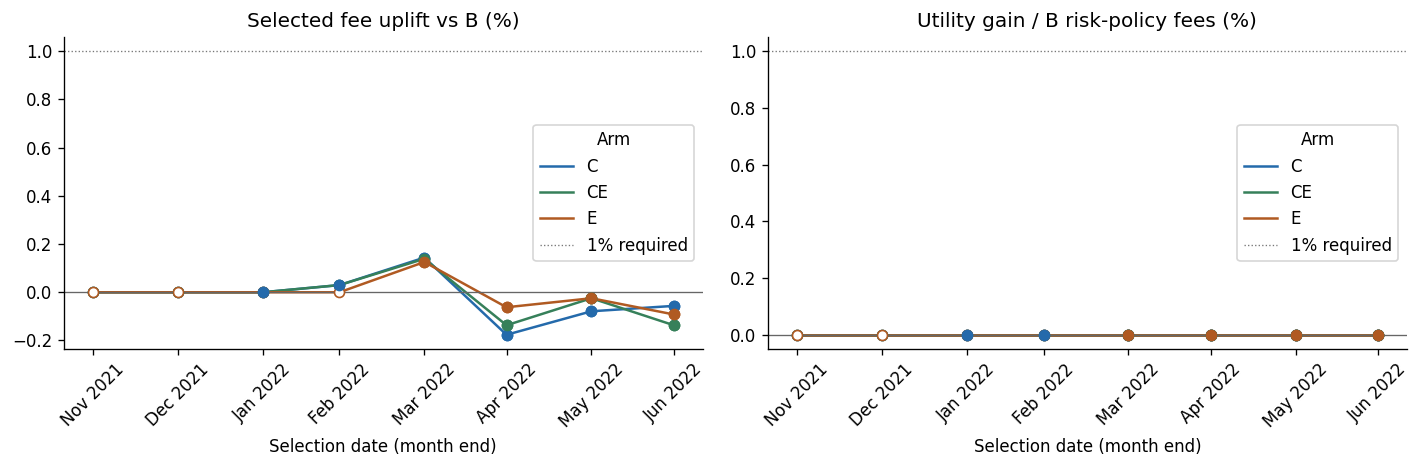

In [6]:
display(table('source_variation'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
colors = {'C': '#246aab', 'E': '#b05a22', 'CE': '#36805a', 'G': '#8b59a3'}
for ax, policy, metric, title in zip(axes, ['return', 'risk'], ['uplift_pct', 'utility_gain_pct'], ['Selected fee uplift vs B (%)', 'Utility gain / B risk-policy fees (%)']):
    for arm, g in primary.loc[primary.policy.eq(policy) & primary.arm.isin(['C','G','E','CG','CE','GE','CGE'])].groupby('arm'):
        color = colors.get(arm)
        ax.plot(g.origin, g[metric], color=color, label=arm, linewidth=1.5)
        ax.scatter(g.origin, g[metric], facecolors='white', edgecolors=color, zorder=3)
        informed = g.loc[g.informative]
        ax.scatter(informed.origin, informed[metric], color=color, zorder=4)
    ax.axhline(0, color='#666666', linewidth=0.8)
    ax.axhline(1, color='#777777', linestyle=':', linewidth=0.8, label='1% required')
    ax.set_title(title)
    ax.set_xticks(models.DEV_ORIGINS, [d.strftime('%b %Y') for d in models.DEV_ORIGINS], rotation=45)
    ax.set_xlabel('Selection date (month end)')
    ax.legend(title='Arm')
fig.tight_layout()
fig.savefig(OUT / 'development_uplift.png', dpi=160, bbox_inches='tight')
plt.show()

In [7]:
accuracy = table('development/forecast_metrics')
display(accuracy.loc[accuracy.cohort.eq('full_pool') & accuracy.risk_lambda.isin([0,1])].groupby(['arm','target']).agg(
    mean_fee_mae=('mae','mean'), mean_wape_pct=('wape_pct','mean'), mean_bias_pct=('bias_pct','mean'), mean_deviance=('deviance','mean')))
display(table('development/risk_calibration').head(20))
display(table('nonoverlapping_schedules'))

mean_fee_mae  mean_wape_pct  mean_bias_pct  mean_deviance
arm     target                                                           
B       return   1068.265502      30.847076      22.298015       0.236290
        risk       13.080157     152.960380     -32.776849       0.582046
C       return   1084.901360      31.274733      21.855355       0.238682
        risk       13.014993     151.760818     -33.917906       0.579836
CE      return   1155.261571      32.981931      17.052657       0.252741
        risk       13.482980     159.067531     -24.993128       0.563576
E       return   1156.735286      32.996660      16.670406       0.253290
        risk       13.576285     160.819941     -23.192082       0.567556
minimal return   1074.753582      31.019051      20.964805       0.236752
repeat  return    831.501900      23.526845       5.257491       0.213660

,origin,arm,risk_decile,merchants,predicted_shortfall,actual_shortfall
0,2021-11-30,B,0,390,0.604204,1.329582
1,2021-11-30,B,1,389,1.138180,3.107951
2,2021-11-30,B,2,390,1.507299,1.667401
3,2021-11-30,B,3,389,1.861510,3.072967
4,2021-11-30,B,4,390,2.209557,2.806664
5,2021-11-30,B,5,389,2.559007,2.343973
6,2021-11-30,B,6,389,2.939918,4.093337
7,2021-11-30,B,7,390,3.444649,4.434633
8,2021-11-30,B,8,389,4.184801,6.773514
9,2021-11-30,B,9,390,8.964567,64.833169


,arm,policy,risk_lambda,window_schedule,origins,mean_delta_fees,mean_uplift_pct,mean_utility_gain_pct
0,B,return,0.0,0,3,0.000000,0.000000,0.000000
1,B,return,0.0,1,3,0.000000,0.000000,0.000000
2,B,return,0.0,2,2,0.000000,0.000000,0.000000
3,B,risk,0.5,0,3,0.000000,0.000000,0.000000
4,B,risk,0.5,1,3,0.000000,0.000000,0.000000
5,B,risk,0.5,2,2,0.000000,0.000000,0.000000
6,B,risk,1.0,0,3,0.000000,0.000000,0.000000
7,B,risk,1.0,1,3,0.000000,0.000000,0.000000
8,B,risk,1.0,2,2,0.000000,0.000000,0.000000
9,B,risk,2.0,0,3,0.000000,0.000000,0.000000


## 5. Placebos, proxies and concentration

Each of 99 fixed-seed repetitions shuffles complete external histories between categories with the same availability pattern. Every enabled subset is refitted. We compare the real candidate with the **best** arm in each placebo, accounting for the opportunity to choose an accidental winner. The percentile is an overfitting diagnostic, not a causal p-value.

Candidates need at least four informative origins spanning two disjoint windows, a 1% economic benefit, positive benefit in 75% of origins and a gain above the placebo threshold. Return must also beat repeat sales. Downside must improve deviance by 1% and retain at least 99% of baseline fees. Source removal, mapping sensitivity and concentration are assessed before freezing.

,arm,policy,informative_origins,nonoverlapping_windows,origins,mean_uplift_pct,mean_delta_fees,mean_repeat_uplift_pct,mean_utility_gain_pct,positive_origins,positive_fraction,score,mean_shortfall_deviance_improvement_pct,fragile,total_contribution,without_largest_merchant,without_largest_category,placebo_95_pct,qualifies,positive_marginal_sources
0,C,return,6,2,"2022-01-31,2022-02-28,2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.023002,-1385.608205,-0.194637,-0.023002,2,0.333333,-0.023002,NaN,False,-8313.649231,-67770.711147,-67770.711147,0.111767,False,False
1,C,risk,6,2,"2022-01-31,2022-02-28,2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.171622,0.000000,0,0.000000,0.000000,0.340204,False,0.000000,0.000000,0.000000,0.000000,False,False
2,CE,return,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.039802,-2367.747515,-0.259226,-0.039802,1,0.250000,-0.039802,NaN,False,-9470.990061,-38077.768792,-58407.400389,0.111767,False,False
3,CE,risk,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.219458,0.000000,0,0.000000,0.000000,-0.996412,False,0.000000,0.000000,0.000000,0.000000,False,False
4,E,return,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.013335,-890.763536,-0.232789,-0.013335,1,0.250000,-0.013335,NaN,False,-3563.054142,-32169.832874,-73020.764570,0.111767,False,False
5,E,risk,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.219458,0.000000,0,0.000000,0.000000,-2.131633,False,0.000000,0.000000,0.000000,0.000000,False,False


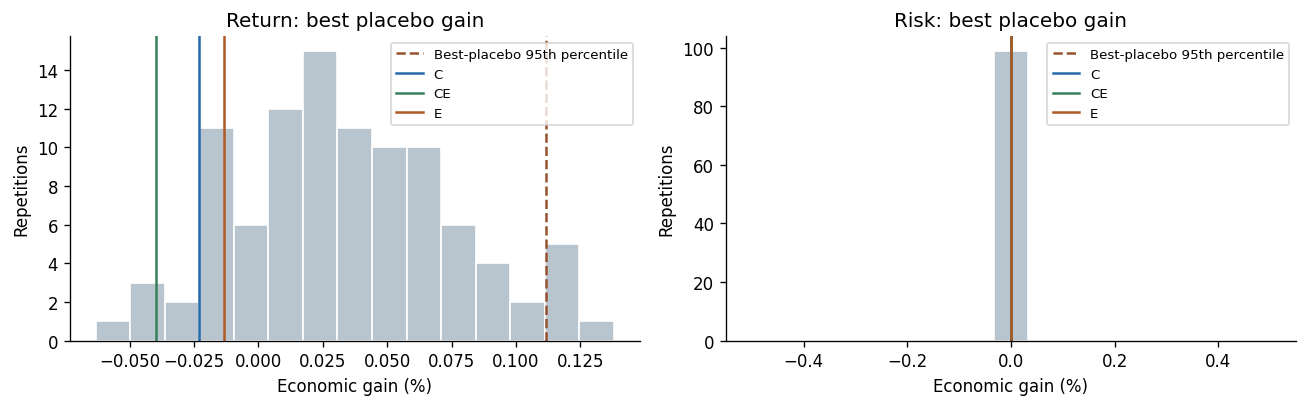

In [8]:
placebos = table('placebo_distribution')
assert len(placebos) == 99 and placebos.repetition.is_unique
summary = table('candidate_decisions')
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, role in zip(axes, ['return','risk']):
    values = placebos['best_' + role]
    ax.hist(values, bins=15, color='#b8c5ce', edgecolor='white')
    ax.axvline(values.quantile(.95), color='#96522d', linestyle='--', label='Best-placebo 95th percentile')
    for i, row in enumerate(summary.loc[summary.policy.eq(role)].itertuples()):
        if np.isfinite(row.score):
            ax.axvline(row.score, color=colors.get(row.arm), label=row.arm)
    ax.set_title(role.capitalize() + ': best placebo gain')
    ax.set_xlabel('Economic gain (%)')
    ax.set_ylabel('Repetitions')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'placebo_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

In [9]:
display(table('strict_mapping_summary'))
display(folds.loc[folds.policy.eq('risk')].groupby(['arm','risk_lambda']).agg(
    mean_fee_uplift_pct=('uplift_pct','mean'), mean_utility_gain_pct=('utility_gain_pct','mean')))
display(summary[['arm','policy','informative_origins','total_contribution','without_largest_merchant','without_largest_category','fragile']])
display(table('development/selection_changes').head(12))

,arm,policy,informative_origins,nonoverlapping_windows,origins,mean_uplift_pct,mean_delta_fees,mean_repeat_uplift_pct,mean_utility_gain_pct,positive_origins,positive_fraction,score,mean_shortfall_deviance_improvement_pct,fragile,total_contribution,without_largest_merchant,without_largest_category
0,C,return,6,2,"2022-01-31,2022-02-28,2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.033056,-1790.656671,-0.199713,-0.033056,0,0.0,-0.033056,NaN,False,-10743.940027,-32945.090455,-32945.090455
1,C,risk,6,2,"2022-01-31,2022-02-28,2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.166651,0.000000,0,0.0,0.000000,-0.070887,False,0.000000,0.000000,0.000000
2,CE,return,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.258042,-14291.914851,-0.477123,-0.258042,0,0.0,-0.258042,NaN,False,-57167.659402,-103762.993038,-113173.516261
3,CE,risk,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.219458,0.000000,0,0.0,0.000000,-0.192695,False,0.000000,0.000000,0.000000
4,E,return,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",-0.258042,-14291.914851,-0.477123,-0.258042,0,0.0,-0.258042,NaN,False,-57167.659402,-103762.993038,-113173.516261
5,E,risk,4,2,"2022-03-31,2022-04-30,2022-05-31,2022-06-30",0.000000,0.000000,-0.219458,0.000000,0,0.0,0.000000,-0.115022,False,0.000000,0.000000,0.000000


mean_fee_uplift_pct  mean_utility_gain_pct
arm risk_lambda                                            
B   0.5                          0.0                    0.0
    1.0                          0.0                    0.0
    2.0                          0.0                    0.0
C   0.5                          0.0                    0.0
    1.0                          0.0                    0.0
    2.0                          0.0                    0.0
CE  0.5                          0.0                    0.0
    1.0                          0.0                    0.0
    2.0                          0.0                    0.0
E   0.5                          0.0                    0.0
    1.0                          0.0                    0.0
    2.0                          0.0                    0.0

,arm,policy,informative_origins,total_contribution,without_largest_merchant,without_largest_category,fragile
0,C,return,6,-8313.649231,-67770.711147,-67770.711147,False
1,C,risk,6,0.000000,0.000000,0.000000,False
2,CE,return,4,-9470.990061,-38077.768792,-58407.400389,False
3,CE,risk,4,0.000000,0.000000,0.000000,False
4,E,return,4,-3563.054142,-32169.832874,-73020.764570,False
5,E,risk,4,0.000000,0.000000,0.000000,False


,merchant_abn,category,actual_fees,actual_shortfall,actual_utility,selected,baseline_selected,fee_contribution,utility_contribution,change,origin,arm,policy,risk_lambda
0,38212167834,"lawn and garden supply outlets, including nurseries",25390.089192,0.0,25390.089192,False,True,-25390.089192,-25390.089192,removed,2021-11-30,repeat,return,0.0
1,70009327857,"lawn and garden supply outlets, including nurseries",23498.343008,0.0,23498.343008,True,False,23498.343008,23498.343008,entered,2021-11-30,repeat,return,0.0
2,29639699851,"lawn and garden supply outlets, including nurseries",19025.988904,0.0,19025.988904,False,True,-19025.988904,-19025.988904,removed,2021-12-31,repeat,return,0.0
3,83199298021,"antique shops - sales, repairs, and restoration services",26216.636310,0.0,26216.636310,True,False,26216.636310,26216.636310,entered,2021-12-31,repeat,return,0.0
4,70009327857,"lawn and garden supply outlets, including nurseries",21712.212780,0.0,21712.212780,False,True,-21712.212780,-21712.212780,removed,2022-01-31,repeat,return,0.0
5,83199298021,"antique shops - sales, repairs, and restoration services",29351.201002,0.0,29351.201002,True,False,29351.201002,29351.201002,entered,2022-01-31,repeat,return,0.0
6,29639699851,"lawn and garden supply outlets, including nurseries",22420.679158,0.0,22420.679158,False,True,-22420.679158,-22420.679158,removed,2022-02-28,C,return,0.0
7,88358066529,health and beauty spas,23900.240410,0.0,23900.240410,True,False,23900.240410,23900.240410,entered,2022-02-28,C,return,0.0
8,29639699851,"lawn and garden supply outlets, including nurseries",22420.679158,0.0,22420.679158,False,True,-22420.679158,-22420.679158,removed,2022-02-28,CE,return,0.0
9,88358066529,health and beauty spas,23900.240410,0.0,23900.240410,True,False,23900.240410,23900.240410,entered,2022-02-28,CE,return,0.0


## 6. Frozen October check

The September 30 decision predicts October 1–26. Training uses first-26-day outcomes from earlier months, completed by that decision date. Its repeat benchmark and downside reference are average first-26-day sales from the previous three months. The internal feature definitions and baseline family-selection rule stay fixed.

No development winner means the corresponding frozen method is B. In that case October compares internal policies and benchmarks and cannot promote a rejected external feature. The check is shorter than the development horizon and cannot establish independent three-month performance.

In [10]:
display(pd.Series(metadata('frozen_candidates'), name='Frozen decision').to_frame())
display(table('confirmation/fold_metrics'))
display(pd.DataFrame(metadata('confirmation/decision')['results']).T)
selected = table('final_selected_merchants')
assert selected.groupby(['arm','policy','risk_lambda']).merchant_abn.nunique().eq(100).all()
display(selected.loc[selected.arm.eq('frozen_selected') & selected.policy.eq('return')].sort_values('rank')[
    ['rank','merchant_abn','category','take_rate','predicted_fees','actual_fees']].head(15))
display(pd.Series(metadata('confirmation_read'), name='October source audit').to_frame())

,Frozen decision
choices,"{'return': 'B', 'risk': 'B'}"
frozen_at,2026-10-12T08:45:37.921738+00:00
evidence,retrospective three-month development
source_status,"{'C': {'status': 'available', 'usable_category_origins': 168, 'provenance': 'verified_..."


,origin,arm,policy,risk_lambda,fees,shortfall,utility,delta_fees,uplift_pct,utility_gain_pct,top100_overlap
0,2022-09-30,B,return,0.0,1.734878e+06,0.0,1.734878e+06,0.000000,0.000000,0.000000,100
1,2022-09-30,B,risk,1.0,1.734878e+06,0.0,1.734878e+06,0.000000,0.000000,0.000000,100
2,2022-09-30,frozen_selected,return,0.0,1.734878e+06,0.0,1.734878e+06,0.000000,0.000000,0.000000,100
3,2022-09-30,frozen_selected,risk,1.0,1.734878e+06,0.0,1.734878e+06,0.000000,0.000000,0.000000,100
4,2022-09-30,minimal,return,0.0,1.735962e+06,0.0,1.735962e+06,1084.146243,0.062491,0.062491,98
5,2022-09-30,repeat,return,0.0,1.736226e+06,0.0,1.736226e+06,1348.564361,0.077733,0.077733,97


,passed,uplift_pct,utility_gain_pct,external_candidate
return,False,0.0,0.0,False
risk,False,0.0,0.0,False


,rank,merchant_abn,category,take_rate,predicted_fees,actual_fees
470,1,79827781481,"furniture, home furnishings and equipment shops, and manufacturers, except appliances",6.82,31403.001303,33164.058655
435,2,45629217853,"gift, card, novelty, and souvenir shops",6.98,30713.591837,29928.641942
420,3,32361057556,"gift, card, novelty, and souvenir shops",6.61,29737.804468,32872.334996
439,4,48534649627,"opticians, optical goods, and eyeglasses",6.64,29306.920117,33060.881723
451,5,63123845164,artist supply and craft shops,6.59,29086.235478,32254.894829
428,6,38700038932,tent and awning shops,6.31,29054.683024,28719.715545
477,7,86578477987,"watch, clock, and jewelry repair shops",6.43,28380.044631,31461.348816
454,8,64403598239,"music shops - musical instruments, pianos, and sheet music",6.31,27850.401497,29506.148996
407,9,21439773999,"cable, satellite, and other pay television and radio services",6.10,27443.359645,30350.169711
493,10,96680767841,motor vehicle supplies and new parts,5.91,27171.597192,30138.519845


,October source audit
opened_at,2026-10-12T08:46:21.519363+00:00
status,complete
source_orders,737632
source_sales,122378461.505824
unique_ids,737632


## 7. Validation and limits

The original baseline, exact source reconciliation, hand-calculated features, temporal availability, deterministic top 100, common missing-source forecasts and independently computed fees are checked in tests and runtime assertions. Actual-data future perturbation checks and prior-baseline reproduction are retained below.

Gross fees exclude defaults, funding and operating costs. Categories and take rates are treated as historically known. Recorded sales proxy hypothetical selection outcomes. The merchant data are synthetic, categories share external signals, and outcome windows overlap. A valid negative result is useful; additional untouched outcomes are needed for a stronger claim.

In [11]:
for name in ['real_data_perturbation_check', 'minimal_reproduction_check', 'reproducibility_check']:
    if (OUT / (name + '.json')).exists():
        display(Markdown('**' + name.replace('_',' ') + '**'))
        display(metadata(name))
display(pd.Series(metadata('runtime_versions'), name='Recorded environment').to_frame())
display(Markdown('Full source links and reproduction details: [EXTERNAL_DATA_COMPARISON.md](../../README.md#external-data-comparison).'))

,Recorded environment
python,"3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]"
numpy,2.3.1
pandas,2.3.0
pyarrow,25.0.0
requests,2.32.3
beautifulsoup4,4.13.4
openpyxl,3.1.5
xlrd,2.0.2
scikit-learn,1.7.2
scipy,1.16.2


Full source links and reproduction details: [EXTERNAL_DATA_COMPARISON.md](../../README.md#external-data-comparison).